# Pump It Up: Predicting Waterpoint Operating Condition with XGBoost

AI7101 — Machine Learning with Python  
Majid Alredha · Hamad Alhosani · Hamdan Alhammadi

This notebook classifies Tanzanian waterpoints as **functional**, **functional needs repair**, or **non-functional** using **XGBoost with balanced training weights and fixed hyperparameters**. It fits all development training records, selects a repair threshold from those training predictions, and evaluates the fixed model and rule on a separate holdout.

The analysis also estimates inspection workload and coverage and creates competition predictions. Run all cells to generate results. The labels describe recorded operating condition; prospective evaluation would be needed to assess future failure or operational benefits.


## 1. Setup and workflow

After data preparation, the modeling workflow has three steps:

1. Fit the fixed XGBoost configuration on **all 53,460 development training records**, using balanced sample weights.
2. Evaluate argmax and all tested repair thresholds using predictions on those same training records; select the rule by macro-F1.
3. Evaluate that model and decision rule on the **5,940-record holdout**.

The best saved settings are fixed at **1,000 boosting rounds**, **learning rate 0.1**, and **depth 10**, together with the remaining settings listed in Section 6. The random seed is **42**; package versions are printed below and results are exported to `outputs/xgboost/`.

The inspection analysis uses holdout predictions. After evaluation, a separate final refit on all 59,400 labeled records produces competition predictions with the same hyperparameters and selected decision rule.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import xgboost
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier


In [2]:
SEED = 42
BATCH_SIZE = 500

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "data" / "raw").is_dir():
    REPO_ROOT = REPO_ROOT.parent
DATA_DIR = REPO_ROOT / "data" / "raw"
if not DATA_DIR.is_dir():
    raise FileNotFoundError("Run from the repository root or notebooks/.")
OUTPUT_DIR = REPO_ROOT / "outputs" / "xgboost"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["functional", "functional needs repair", "non functional"]
label_to_number = {name: number for number, name in enumerate(CLASS_NAMES)}
number_to_label = {number: name for name, number in label_to_number.items()}

sns.set_theme(style="whitegrid")
sklearn.set_config(working_memory=128)

print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)


scikit-learn: 1.9.1
XGBoost: 3.4.1


## 2. Load and align the data

The dataset contains **59,400 labeled waterpoints**, **39 predictor fields**, and **14,850 unlabeled competition records**. Predictors describe location, infrastructure, water availability, funding, and management. Labels are joined by waterpoint `id`, with checks for unique IDs, complete labels, and consistent columns.

The identifier is excluded from model inputs. The target is encoded as follows:

| Label | Operating condition | Training records | Share |
|---|---|---:|---:|
| `0` | Functional | 32,259 | 54.31% |
| `1` | Functional needs repair | 4,317 | 7.27% |
| `2` | Non-functional | 22,824 | 38.42% |

Competition records are used only for final prediction. Field and target definitions follow the [DrivenData dataset documentation](https://www.drivendata.org/competitions/7/pump-it-up-data-mining-the-water-table/page/25/).


In [3]:
train_values = pd.read_csv(DATA_DIR / "train_values.csv")
train_labels = pd.read_csv(DATA_DIR / "train_labels.csv")
test_values = pd.read_csv(DATA_DIR / "test_values.csv")
submission_format = pd.read_csv(DATA_DIR / "submission_format.csv")

# Verify unique IDs, aligned labels, disjoint train/test records, and matching fields.
for frame in [train_values, train_labels, test_values, submission_format]:
    assert frame["id"].is_unique

assert set(train_values["id"]) == set(train_labels["id"])
assert set(test_values["id"]) == set(submission_format["id"])
assert set(train_values["id"]).isdisjoint(test_values["id"])
assert set(train_values.columns) == set(test_values.columns)

df = train_values.merge(train_labels, on="id", how="left", validate="one_to_one")

assert df["status_group"].notna().all()
assert set(df["status_group"]) == set(CLASS_NAMES)

# Exclude the target and identifier from model inputs.
X = df.drop(columns=["id", "status_group"])

# 0 = functional; 1 = functional needs repair; 2 = non-functional.
y = df["status_group"].map(label_to_number).astype(int)

X_test = test_values.drop(columns="id")

print("Training inputs:", X.shape)
print("Training target:", y.shape)
print("Competition test inputs:", X_test.shape)

display(df.head())


Training inputs: (59400, 39)
Training target: (59400,)
Competition test inputs: (14850, 39)


,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,...,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group,status_group
0,69572,6000.0,2011-03-14,Roman,1390,Roman,34.938093,-9.856322,none,0,...,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe,functional
1,8776,0.0,2013-03-06,Grumeti,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,...,soft,good,insufficient,insufficient,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional
2,34310,25.0,2013-02-25,Lottery Club,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,...,soft,good,enough,enough,dam,dam,surface,communal standpipe multiple,communal standpipe,functional
3,67743,0.0,2013-01-28,Unicef,263,UNICEF,38.486161,-11.155298,Zahanati Ya Nanyumbu,0,...,soft,good,dry,dry,machine dbh,borehole,groundwater,communal standpipe multiple,communal standpipe,non functional
4,19728,0.0,2011-07-13,Action In A,0,Artisan,31.130847,-1.825359,Shuleni,0,...,soft,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional


## 3. Reserve a 10% holdout set

A seeded, stratified split assigns **53,460 records (90%)** to development training and **5,940 records (10%)** to the holdout. Exploration, preprocessing, model fitting, and threshold selection use development training records.

All development training records are used in one XGBoost fit. Its predictions on those same records provide the threshold-tuning scores. The holdout is excluded from fitting and threshold selection and evaluates the fixed model and chosen decision rule.


In [4]:
# Reserve a stratified holdout before exploration and model fitting.

X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    X, y, test_size=0.10, stratify=y, random_state=SEED
)

eda = X_dev.copy()
eda["status_group"] = y_dev.map(number_to_label)

print("Development rows:", len(X_dev))
print("Holdout rows:", len(X_holdout))

class_summary = eda["status_group"].value_counts().to_frame("count")
class_summary["percent"] = 100 * class_summary["count"] / len(eda)

display(class_summary)


Development rows: 53460
Holdout rows: 5940


,count,percent
status_group,,
functional,29033,54.307894
non functional,20542,38.424991
functional needs repair,3885,7.267116


## 4. Explore the development data

Repair cases account for only **7.27%** of development records. This imbalance motivates balanced training weights and evaluation beyond accuracy.

`scheme_name` is missing in **48.50%** of development records. Waterpoint names, subvillages, and wards also have many distinct values, making sparsely represented categories difficult to estimate reliably.

Literal missingness does not capture every data-quality issue. Nonpositive construction years and invalid coordinate pairs require validity rules before imputation.


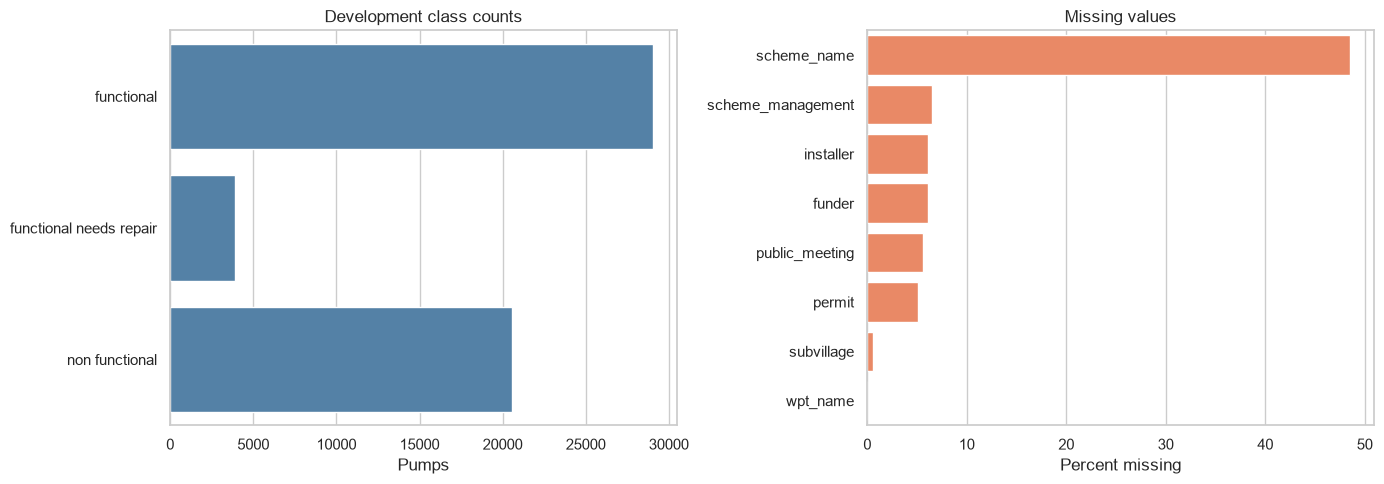

In [5]:
# Show class imbalance and literal missingness before applying validity rules.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=eda, y="status_group", order=CLASS_NAMES, color="steelblue", ax=axes[0]
)
axes[0].set(title="Development class counts", xlabel="Pumps", ylabel="")

missing = X_dev.isna().mean().mul(100).sort_values(ascending=False)
missing = missing[missing > 0]

sns.barplot(x=missing.values, y=missing.index, color="coral", ax=axes[1])
axes[1].set(title="Missing values", xlabel="Percent missing", ylabel="")

plt.tight_layout()
plt.show()


In [6]:
display(
    pd.DataFrame(
        {"unique_values": X_dev.nunique(), "missing_percent": X_dev.isna().mean() * 100}
    )
)


,unique_values,missing_percent
amount_tsh,96,0.000000
date_recorded,350,0.000000
funder,1818,6.116723
gps_height,2413,0.000000
installer,2043,6.141040
longitude,51767,0.000000
latitude,51767,0.000000
wpt_name,34072,0.003741
num_private,60,0.000000
basin,9,0.000000


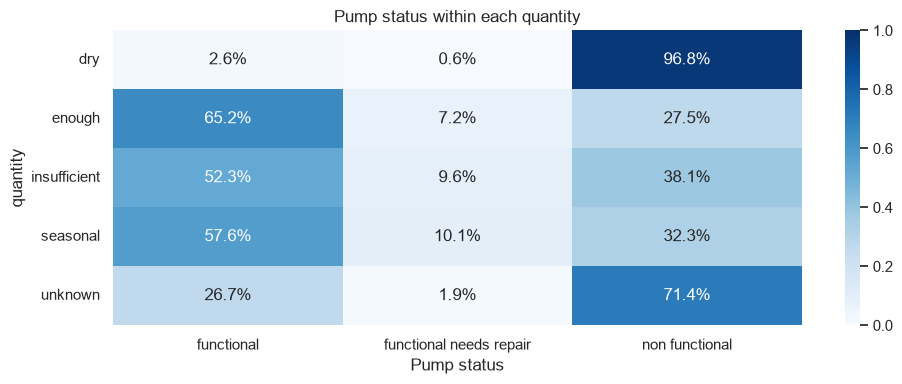

In [7]:
# Compare within-category proportions alongside category counts.


def plot_status_by_category(feature):
    proportions = pd.crosstab(
        eda[feature], eda["status_group"], normalize="index"
    ).reindex(columns=CLASS_NAMES, fill_value=0)

    plt.figure(figsize=(10, 4))

    sns.heatmap(proportions, annot=True, fmt=".1%", cmap="Blues", vmin=0, vmax=1)

    plt.title(f"Pump status within each {feature}")
    plt.xlabel("Pump status")
    plt.tight_layout()
    plt.show()


plot_status_by_category("quantity")


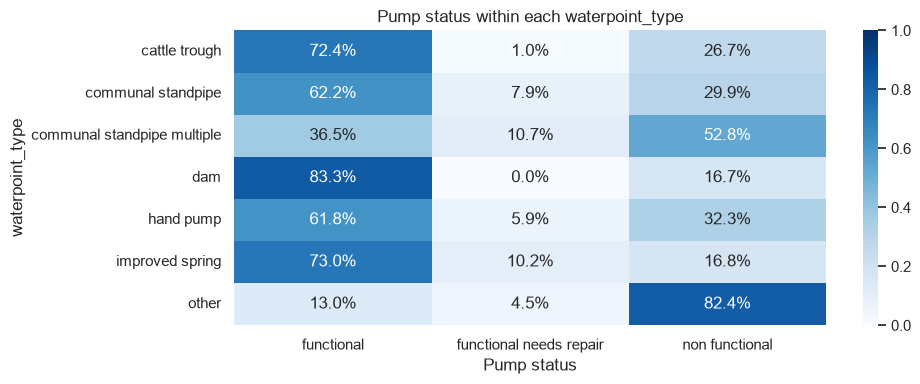

In [8]:
plot_status_by_category("waterpoint_type")


In [9]:
for feature in ["quantity", "waterpoint_type"]:
    display(eda[feature].value_counts().to_frame("pumps"))


,pumps
quantity,
enough,29820
insufficient,13666
dry,5603
seasonal,3648
unknown,723


,pumps
waterpoint_type,
communal standpipe,25661
hand pump,15771
other,5756
communal standpipe multiple,5453
improved spring,708
cattle trough,105
dam,6


### Interpretation of the exploratory analysis

Water availability is strongly associated with operating condition: **96.8% of dry waterpoints** are non-functional. Waterpoint type also separates groups; **82.4% of the `other` category** is non-functional. These patterns support retaining both predictors and considering nonlinear models.

Category counts qualify these percentages. Only **six development records** have waterpoint type `dam`, so their proportions offer little evidence about future cases. Geographic clustering motivates validation across regions as well as random splits. These descriptive associations do not establish causation.


## 5. Prepare features

Deterministic rules applied to each row produce **37 input fields before encoding** for development, holdout, and competition data. These transformations use neither target labels nor statistics from other records.

Imputation, rare-category grouping, and encoding are learned within the XGBoost pipeline using only the training records supplied to each fit.


### Feature-engineering decisions

| Transformation | Rationale |
|---|---|
| Drop `recorded_by` and `quantity_group` | The first is constant in development data; the second exactly duplicates `quantity`. |
| Drop `wpt_name`, `subvillage`, and raw `scheme_name` | Reduce sparsely supported categories; retain scheme-name availability through `scheme_name_missing`. |
| Replace `ward` with `ward_id` combining LGA and ward | Distinguish repeated ward names while retaining local information. |
| Retain `source_class` and `extraction_type_class` | Provide broader representations alongside detailed source and extraction fields; remove other overlapping grouped variants. |
| Validate construction year; derive pump age and recording year | Treat nonpositive years and construction after recording as missing; represent age and collection period. |
| Encode recording month with sine and cosine | Represent seasonality while keeping December and January adjacent. |
| Flag and replace invalid coordinate pairs | Zero longitude, latitude within 0.000001° of zero, or a missing coordinate marks the pair as missing. |
| Add coordinate-grid IDs at 0.05° and 0.10° resolution | Represent local context alongside continuous coordinates; invalid pairs remain missing. |
| Add zero indicators for population, elevation, and `amount_tsh` | Preserve potentially informative zeros without treating every zero as missing. |
| Replace population and `amount_tsh` with `log1p` versions | Reduce skew after clipping negative values to zero. `amount_tsh` denotes total static head in the dataset documentation. |
| Combine region and district codes into `district_id` | Represent administrative codes as categories rather than numeric distances. |
| Normalize categorical text | Standardize case and surrounding whitespace; treat empty strings as missing. |

The following original predictors remain alongside the engineered features:

| Information | Retained fields |
|---|---|
| Location and elevation | `longitude`, `latitude`, `gps_height`, `basin`, `region`, `lga` |
| Funding and installation | `funder`, `installer` |
| Administration and community | `num_private`, `public_meeting`, `scheme_management`, `management`, `permit`, `payment` |
| Infrastructure and water | `construction_year`, `extraction_type`, `extraction_type_class`, `water_quality`, `quantity`, `source`, `source_class`, `waterpoint_type` |

Recording date, raw ward, region and district codes, population, and `amount_tsh` are replaced by their engineered representations. Coordinate grids use angular units rather than fixed physical distances.


In [10]:
# Apply deterministic row-level rules; learn imputation and encoding in the training pipeline.

DROP_COLUMNS = [
    "recorded_by",  # Constant in these data.
    "wpt_name",  # Many nearly unique names.
    "subvillage",  # High cardinality.
    "scheme_name",  # High cardinality and substantial missingness.
    "ward",  # Replaced by a ward identifier qualified by LGA.
    "quantity_group",  # Duplicate of quantity.
    "extraction_type_group",
    "management_group",
    "payment_type",
    "quality_group",
    "source_type",
    "waterpoint_type_group",
]

# Confirm the constant field and exact duplicate using development records.
assert X_dev["recorded_by"].nunique(dropna=False) == 1
assert X_dev["quantity"].equals(X_dev["quantity_group"])


def engineer_features(frame):
    data = frame.copy()

    # Normalize categories before constructing location and missingness features.
    categorical = data.select_dtypes(include=["object", "string", "bool"]).columns
    for column in categorical:
        data[column] = (
            data[column]
            .map(
                lambda value: str(value).strip().lower() if pd.notna(value) else np.nan
            )
            .replace("", np.nan)
        )

    data["ward_id"] = data["lga"].str.cat(data["ward"], sep="::")
    data["scheme_name_missing"] = data["scheme_name"].isna().astype(int)

    # Year 0 is invalid; construction after observation is inconsistent.
    recorded = pd.to_datetime(data["date_recorded"], errors="coerce")
    year = pd.to_numeric(data["construction_year"], errors="coerce")
    year = year.mask((year <= 0) | (year > recorded.dt.year))

    data["construction_year"] = year
    data["pump_age"] = recorded.dt.year - year
    data["record_year"] = recorded.dt.year

    # Cyclic month features place December near January.
    month = recorded.dt.month
    data["month_sin"] = np.sin(2 * np.pi * (month - 1) / 12)
    data["month_cos"] = np.cos(2 * np.pi * (month - 1) / 12)

    # Replace zero-longitude, near-zero-latitude, or incomplete coordinate pairs.
    bad_coordinates = (
        data["longitude"].eq(0)
        | np.isclose(data["latitude"], 0, atol=1e-6)
        | data[["longitude", "latitude"]].isna().any(axis=1)
    )

    data["coordinates_missing"] = bad_coordinates.astype(int)
    data.loc[bad_coordinates, ["longitude", "latitude"]] = np.nan

    # Geographic cells capture local context at two angular resolutions.
    for name, cell_size in [("geo_grid_005", 0.05), ("geo_grid_010", 0.10)]:
        longitude_cell = np.floor(data["longitude"] / cell_size).astype("Int64")
        latitude_cell = np.floor(data["latitude"] / cell_size).astype("Int64")
        data[name] = (
            longitude_cell.astype(str) + "::" + latitude_cell.astype(str)
        ).mask(bad_coordinates)

    # Preserve ambiguous zeros and give models explicit zero indicators.
    for column in ["population", "gps_height", "amount_tsh"]:
        data[column + "_is_zero"] = data[column].eq(0).astype(int)

    # Clip negative values and log-transform population and static head.
    for column in ["population", "amount_tsh"]:
        data[column + "_log1p"] = np.log1p(data[column].clip(lower=0))

    # Administrative codes are category labels, not numeric distances.
    data["district_id"] = (
        data["region_code"].astype(str) + "_" + data["district_code"].astype(str)
    )

    data = data.drop(
        columns=DROP_COLUMNS
        + ["date_recorded", "region_code", "district_code", "population", "amount_tsh"]
    )

    return data


X_dev_clean = engineer_features(X_dev)
X_holdout_clean = engineer_features(X_holdout)
X_test_clean = engineer_features(X_test)

display(X_dev_clean.head())
print("Prepared development shape:", X_dev_clean.shape)


,funder,gps_height,installer,longitude,latitude,num_private,basin,region,lga,public_meeting,...,month_cos,coordinates_missing,geo_grid_005,geo_grid_010,population_is_zero,gps_height_is_zero,amount_tsh_is_zero,population_log1p,amount_tsh_log1p,district_id
779,jaica,57,jaica,39.581692,-9.725771,0,ruvuma / southern coast,lindi,lindi rural,false,...,1.000000,0,791::-195,395::-98,0,0,0,0.693147,3.931826,80_23
11237,world bank,0,rhobi,36.894605,-5.960452,0,wami / ruvu,dodoma,kongwa,true,...,0.500000,0,737::-120,368::-60,1,1,1,0.000000,0.000000,1_3
24337,private individual,1861,dmdd,35.838990,-3.233549,0,internal,arusha,karatu,true,...,0.500000,0,716::-65,358::-33,0,0,0,5.017280,2.397895,24_30
40212,world bank,1331,world bank,30.017050,-4.335164,0,lake tanganyika,kigoma,kasulu,true,...,0.866025,0,600::-87,300::-44,0,0,0,5.771441,5.525453,16_2
15237,lifetime,27,artisan,39.172887,-8.528037,0,ruvuma / southern coast,lindi,kilwa,true,...,0.866025,0,783::-171,391::-86,0,0,1,5.802118,0.000000,80_13


Prepared development shape: (53460, 37)


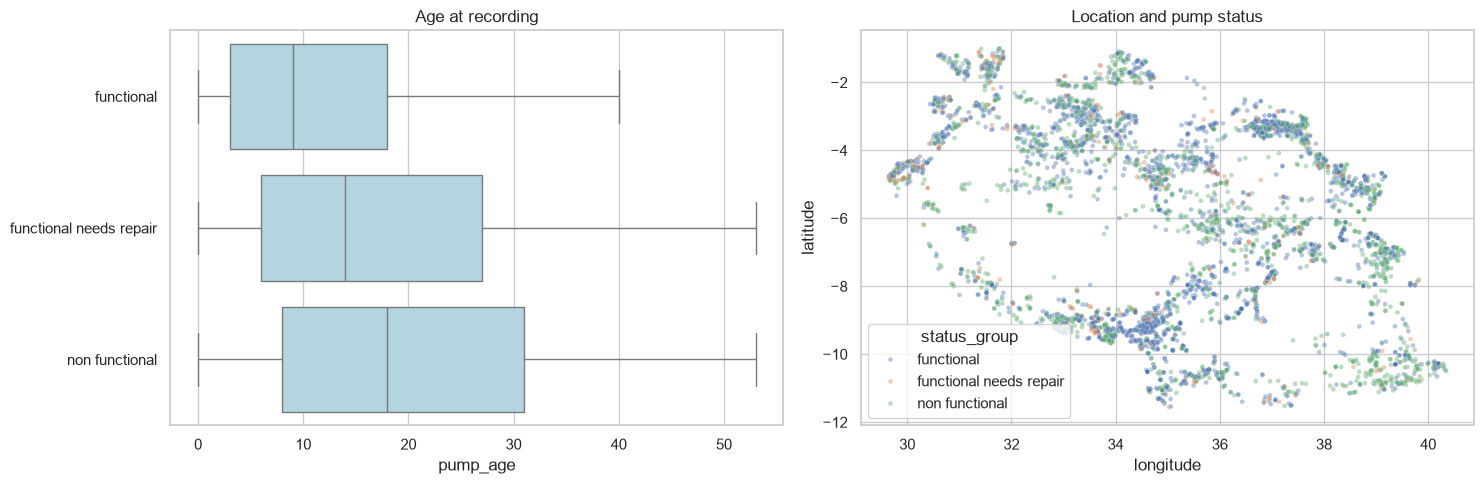

In [11]:
# Explore pump age and spatial patterns in the development data.

plot_data = X_dev_clean.copy()
plot_data["status_group"] = y_dev.map(number_to_label)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(
    data=plot_data,
    x="pump_age",
    y="status_group",
    order=CLASS_NAMES,
    showfliers=False,
    color="lightblue",
    ax=axes[0],
)
axes[0].set(title="Age at recording", ylabel="")

sample = plot_data.sample(n=min(5000, len(plot_data)), random_state=SEED)

sns.scatterplot(
    data=sample,
    x="longitude",
    y="latitude",
    hue="status_group",
    hue_order=CLASS_NAMES,
    alpha=0.4,
    s=12,
    ax=axes[1],
)
axes[1].set_title("Location and pump status")

plt.tight_layout()
plt.show()


## 6. Fit balanced XGBoost on all training data

Fit a single XGBoost pipeline on **all 53,460 development training records**. The hyperparameters below are fixed to the best saved configuration. Preprocessing and the classifier are learned from those training records; the holdout is excluded.


### Fixed hyperparameters and balanced weights

| Setting | Fixed value |
|---|---|
| Boosting rounds (`n_estimators`) | 1,000 |
| Learning rate | 0.1 |
| Maximum depth | 10 |
| Minimum child weight | 2 |
| Gamma | 0.1 |
| Row and feature sampling (`subsample`, `colsample_bytree`) | 0.9 each |
| L1 and L2 regularization (`reg_alpha`, `reg_lambda`) | 0.1 and 0.5 |
| Objective, evaluation metric, tree method | `multi:softprob`, `mlogloss`, `hist` |
| Classes, random seed, threads | 3, 42, 2 |

No early stopping is applied. Balanced sample weights are passed directly to the classifier through the pipeline:

$$w_k = \frac{n}{K n_k}, \qquad K=3,$$

where $n$ is the number of training records and $n_k$ is the count in class $k$. `compute_sample_weight("balanced", y_dev)` supplies weights for the development training fit. The final competition refit recomputes them from all labeled records.

For all 59,400 labeled records, the corresponding weights are approximately **0.614**, **4.587**, and **0.868** for functional, repair, and non-functional respectively. Weights affect training; reported metrics remain unweighted.


### Preprocessing learned from the training data

Numeric features use median imputation with indicators for missingness observed during fitting. Categorical missing values receive `__missing__`, followed by one-hot encoding so nominal categories have no imposed order.

Categories appearing fewer than 20 times in the training data share an infrequent category. LGA, district, qualified ward, and coordinate-grid fields have no additional category cap. Funder and installer each allow up to 300 encoded categories; other categorical fields allow up to 50. Caps include the infrequent category, which also receives unseen values when available; otherwise, their indicators are all zero. Grouping limits feature count but can remove useful local detail.

XGBoost uses unscaled numeric inputs because its tree splits do not require standardization. The encoded matrix is sparse to limit memory use; its width depends on the categories learned in each fit.


In [12]:
# Define preprocessing; the pipeline learns its statistics from training data only.
numeric_columns = X_dev_clean.select_dtypes(include="number").columns.tolist()
categorical_columns = X_dev_clean.columns.difference(numeric_columns).tolist()
geographic_columns = ["lga", "district_id", "ward_id", "geo_grid_005", "geo_grid_010"]
organisation_columns = ["funder", "installer"]
other_categorical_columns = [
    column
    for column in categorical_columns
    if column not in geographic_columns + organisation_columns
]


def make_categorical_pipeline(max_categories):
    return Pipeline(
        [
            ("impute", SimpleImputer(strategy="constant", fill_value="__missing__")),
            (
                "encode",
                OneHotEncoder(
                    handle_unknown="infrequent_if_exist",
                    min_frequency=20,
                    max_categories=max_categories,
                    sparse_output=True,
                ),
            ),
        ]
    )


preprocess = ColumnTransformer(
    [
        (
            "numeric",
            SimpleImputer(strategy="median", add_indicator=True),
            numeric_columns,
        ),
        ("geographic", make_categorical_pipeline(None), geographic_columns),
        ("organisation", make_categorical_pipeline(300), organisation_columns),
        ("categorical", make_categorical_pipeline(50), other_categorical_columns),
    ],
    sparse_threshold=1.0,
)


def predict_probabilities_in_batches(model, frame):
    """Limit memory use when predicting class probabilities."""
    return np.concatenate(
        [
            model.predict_proba(frame.iloc[start : start + BATCH_SIZE])
            for start in range(0, len(frame), BATCH_SIZE)
        ]
    )


In [13]:
# Use the best saved hyperparameters as fixed settings.
XGBOOST_PARAMETERS = {
    "n_estimators": 1000,
    "learning_rate": 0.1,
    "max_depth": 10,
    "min_child_weight": 2,
    "gamma": 0.1,
    "subsample": 0.9,
    "colsample_bytree": 0.9,
    "reg_alpha": 0.1,
    "reg_lambda": 0.5,
    "objective": "multi:softprob",
    "num_class": 3,
    "eval_metric": "mlogloss",
    "tree_method": "hist",
    "random_state": SEED,
    "n_jobs": 2,
}
model = Pipeline(
    [("preprocess", preprocess), ("model", XGBClassifier(**XGBOOST_PARAMETERS))]
)

# Fit once on all development training rows with balanced sample weights.
assert X_dev_clean.index.intersection(X_holdout_clean.index).empty
training_weights = compute_sample_weight("balanced", y_dev)
model.fit(X_dev_clean, y_dev, model__sample_weight=training_weights)

# Reuse these probabilities for every tested threshold.
training_probabilities = predict_probabilities_in_batches(model, X_dev_clean)
classes = np.asarray(model.classes_)
assert training_probabilities.shape == (len(y_dev), len(classes))
assert np.isfinite(training_probabilities).all()
print("Training rows fitted and predicted:", len(y_dev))


Training rows fitted and predicted: 53460


## 7. Select the repair threshold

Evaluate **argmax** and **91 repair thresholds from 0.05 to 0.95** using the probabilities already generated for all development training records. Argmax selects the most probable class. A repair threshold predicts repair when its probability reaches the threshold; otherwise, it selects the more probable of functional and non-functional.

Rank rules by **macro-F1**, then accuracy, repair recall, and preference for argmax. Macro-F1 averages class-specific F1 scores equally, giving the rare repair class the same importance as each larger class. The holdout does not influence the chosen threshold.

These are **in-sample training scores** and can be optimistic. The next section evaluates the selected rule on the separate holdout. The chart shows threshold trade-offs with dotted argmax references. Scores and the selected rule are exported to `threshold_search.csv` and `xgboost_threshold_summary.csv`.


,rule,repair_threshold,macro_f1,accuracy,repair_precision,repair_recall,default_macro_f1,macro_f1_gain
65,repair_threshold,0.69,0.8499,0.8878,0.7312,0.7799,0.8134,0.0365


Selected prediction rule: repair_threshold
Selected repair threshold: 0.69
Training threshold-tuning macro-F1: 0.8499


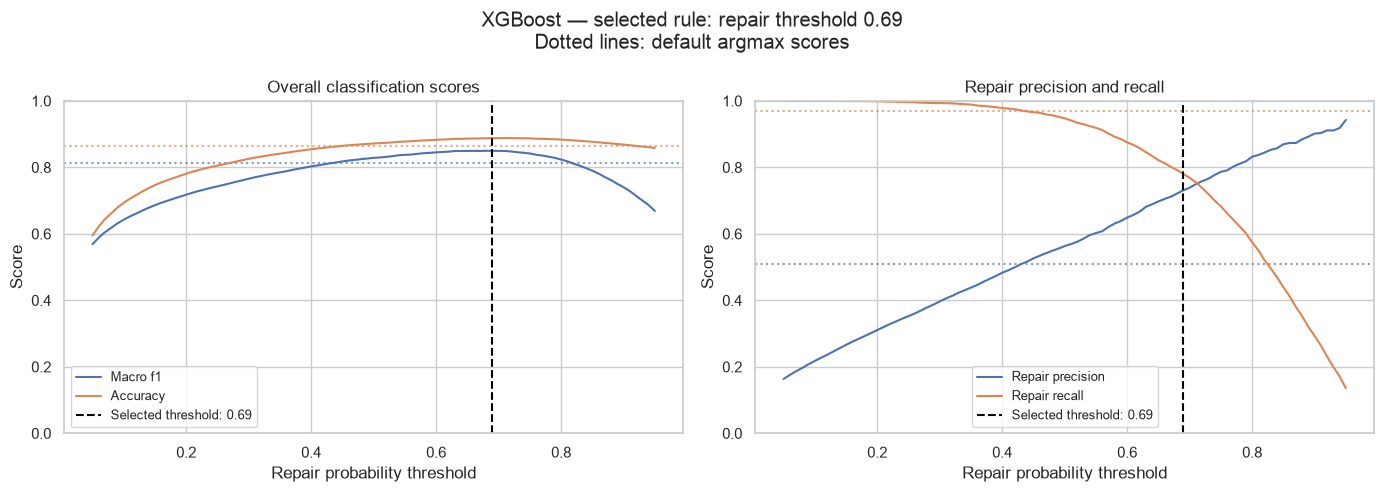

In [14]:
def predict_with_repair_threshold(probabilities, classes, threshold=None):
    classes = np.asarray(classes)
    if threshold is None:
        return classes[np.argmax(probabilities, axis=1)]
    repair_column = np.flatnonzero(classes == 1).item()
    other_columns = np.flatnonzero(classes != 1)
    predictions = classes[
        other_columns[np.argmax(probabilities[:, other_columns], axis=1)]
    ]
    predictions[probabilities[:, repair_column] >= threshold] = 1
    return predictions


threshold_rows = []
repair_thresholds = [None] + np.round(np.linspace(0.05, 0.95, 91), 2).tolist()
for threshold in repair_thresholds:
    predictions = predict_with_repair_threshold(
        training_probabilities, classes, threshold
    )
    threshold_rows.append(
        {
            "rule": "default_argmax" if threshold is None else "repair_threshold",
            "repair_threshold": threshold,
            "macro_f1": f1_score(
                y_dev, predictions, average="macro", zero_division=0
            ),
            "accuracy": accuracy_score(y_dev, predictions),
            "repair_precision": precision_score(
                y_dev, predictions, labels=[1], average="macro", zero_division=0
            ),
            "repair_recall": recall_score(
                y_dev, predictions, labels=[1], average="macro", zero_division=0
            ),
            "prefer_default": int(threshold is None),
        }
    )

threshold_results = pd.DataFrame(threshold_rows).sort_values(
    ["macro_f1", "accuracy", "repair_recall", "prefer_default"],
    ascending=False,
    kind="stable",
).drop(columns="prefer_default")
best_rule = threshold_results.iloc[0]
selected_repair_threshold = (
    None
    if best_rule["rule"] == "default_argmax"
    else float(best_rule["repair_threshold"])
)
argmax_scores = threshold_results.loc[
    threshold_results["rule"] == "default_argmax"
].iloc[0]
threshold_summary = threshold_results.head(1).copy()
threshold_summary["default_macro_f1"] = argmax_scores["macro_f1"]
threshold_summary["macro_f1_gain"] = (
    threshold_summary["macro_f1"] - argmax_scores["macro_f1"]
)
threshold_results.to_csv(OUTPUT_DIR / "threshold_search.csv", index=False)
threshold_summary.to_csv(OUTPUT_DIR / "xgboost_threshold_summary.csv", index=False)
display(threshold_summary.round(4))
print("Selected prediction rule:", best_rule["rule"])
print("Selected repair threshold:", selected_repair_threshold)
print("Training threshold-tuning macro-F1:", round(best_rule["macro_f1"], 4))

# Plot all tested thresholds and the default argmax reference.
curves = threshold_results.loc[
    threshold_results["rule"] == "repair_threshold"
].sort_values("repair_threshold")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metrics in zip(
    axes, [("macro_f1", "accuracy"), ("repair_precision", "repair_recall")]
):
    for metric in metrics:
        (line,) = ax.plot(
            curves["repair_threshold"], curves[metric],
            label=metric.replace("_", " ").capitalize(),
        )
        ax.axhline(
            argmax_scores[metric], color=line.get_color(), linestyle=":", alpha=0.7
        )
    if selected_repair_threshold is not None:
        ax.axvline(
            selected_repair_threshold, color="black", linestyle="--",
            label=f"Selected threshold: {selected_repair_threshold:.2f}",
        )
    ax.set(xlabel="Repair probability threshold", ylabel="Score", ylim=(0, 1))
    ax.legend(fontsize=9)
axes[0].set_title("Overall classification scores")
axes[1].set_title("Repair precision and recall")
rule_label = (
    "default argmax" if selected_repair_threshold is None
    else f"repair threshold {selected_repair_threshold:.2f}"
)
fig.suptitle(f"XGBoost — selected rule: {rule_label}\nDotted lines: default argmax scores")
fig.tight_layout()
plt.show()


## 8. Evaluate the holdout

Apply the selected repair decision rule to the same fitted XGBoost model's probabilities for **5,940 holdout records**. These records were excluded from model fitting and threshold selection. The model is not refitted and the threshold is not changed for this evaluation.

The score table reports accuracy and macro-F1; the classification report provides precision, recall, and F1 for each class. Confusion matrices show counts and proportions within each actual class.

Repair cases predicted as non-functional still get flagged by the inspection policy despite their incorrect three-class label. Classification accuracy and inspection coverage therefore measure different outcomes.


,model,holdout_accuracy,holdout_macro_f1
0,XGBoost,0.805556,0.709434


                         precision    recall  f1-score   support

             functional       0.83      0.85      0.84      3226
functional needs repair       0.47      0.47      0.47       432
         non functional       0.83      0.81      0.82      2282

               accuracy                           0.81      5940
              macro avg       0.71      0.71      0.71      5940
           weighted avg       0.81      0.81      0.81      5940



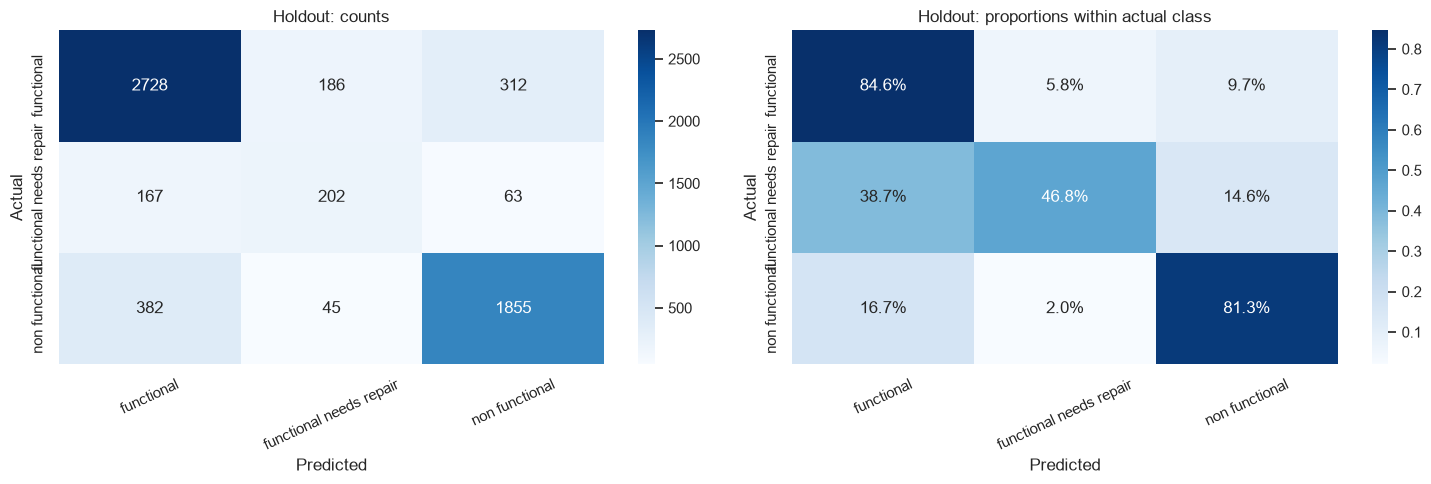

In [15]:
# Evaluate the already-fitted model with the threshold chosen from training data.
holdout_probabilities = predict_probabilities_in_batches(model, X_holdout_clean)
holdout_pred = predict_with_repair_threshold(
    holdout_probabilities, classes, selected_repair_threshold
)

final_scores = pd.DataFrame(
    [
        {
            "model": "XGBoost",
            "holdout_accuracy": accuracy_score(y_holdout, holdout_pred),
            "holdout_macro_f1": f1_score(
                y_holdout, holdout_pred, average="macro", zero_division=0
            ),
        }
    ]
)
display(final_scores)
final_scores.to_csv(OUTPUT_DIR / "holdout_scores.csv", index=False)

print(
    classification_report(
        y_holdout,
        holdout_pred,
        labels=[0, 1, 2],
        target_names=CLASS_NAMES,
        zero_division=0,
    )
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, normalization, title, number_format in [
    (axes[0], None, "Holdout: counts", "d"),
    (axes[1], "true", "Holdout: proportions within actual class", ".1%"),
]:
    matrix = confusion_matrix(
        y_holdout, holdout_pred, labels=[0, 1, 2], normalize=normalization
    )

    sns.heatmap(
        matrix,
        annot=True,
        fmt=number_format,
        cmap="Blues",
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        ax=ax,
    )

    ax.set(title=title, xlabel="Predicted", ylabel="Actual")
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()


## 9. Practical impact: prioritizing inspections

The model prioritizes waterpoints for inspection using the following rule:

- **Predicted functional:** skip inspection.
- **Predicted functional needs repair or non-functional:** select for inspection.

An **attention case** has an actual label of functional needs repair or non-functional. Holdout labels let us estimate inspection workload, coverage, and missed cases.

A repair case predicted as non-functional still gets selected for inspection. This is why inspection coverage differs from correctly predicting all three classes.


In [16]:
# Classes 1 (repair) and 2 (non-functional) count as attention cases.
actual_attention = y_holdout.to_numpy() != 0
selected = holdout_pred != 0

total_sites = len(y_holdout)
sites_selected = int(selected.sum())
attention_total = int(actual_attention.sum())
attention_selected = int(np.sum(selected & actual_attention))
attention_missed = int(np.sum(~selected & actual_attention))
functional_selected = int(np.sum(selected & ~actual_attention))

sites_selected_share = sites_selected / max(total_sites, 1)
coverage = attention_selected / max(attention_total, 1)

display(
    pd.DataFrame(
        {
            "Measure": [
                "Sites selected for inspection",
                "Attention cases selected",
                "Attention cases missed",
                "Functional sites selected",
            ],
            "Result": [
                f"{sites_selected:,} of {total_sites:,} ({sites_selected_share:.2%})",
                f"{attention_selected:,} of {attention_total:,} ({coverage:.2%})",
                f"{attention_missed:,}",
                f"{functional_selected:,}",
            ],
        }
    ).set_index("Measure")
)


,Result
Measure,
Sites selected for inspection,"2,663 of 5,940 (44.83%)"
Attention cases selected,"2,165 of 2,714 (79.77%)"
Attention cases missed,549
Functional sites selected,498


### Inspection workload and coverage

The table above is generated from the current holdout predictions. It reports the share of sites selected for inspection, the share of actual attention cases reached, the attention cases missed, and functional sites selected unnecessarily.

Use these results to assess the trade-off between inspection workload and coverage. They estimate outcomes from recorded operating-condition labels; a field evaluation would be needed to establish actual maintenance benefits.


## 10. Refit and create the submission

After holdout evaluation, the fixed XGBoost configuration is fitted on **all 59,400 labeled waterpoints**. Balanced weights are recomputed from all training labels, and the selected repair decision rule is preserved. Holdout scores describe the development-trained model, not this final refit.

Predictions are converted to the exact competition labels and aligned with the submission template by `id`. Checks verify submission structure, ID order, and valid labels. The exported `outputs/xgboost/submission.csv` contains **14,850 predictions**.

Batched prediction limits memory use. The decision rule receives no further tuning; competition labels are unavailable for local evaluation.


In [17]:
# Refit on all labels with the same fixed hyperparameters and selected threshold.
final_model = clone(model)
final_model.fit(
    engineer_features(X), y,
    model__sample_weight=compute_sample_weight("balanced", y),
)
test_probabilities = predict_probabilities_in_batches(final_model, X_test_clean)
test_predictions = predict_with_repair_threshold(
    test_probabilities, final_model.classes_, selected_repair_threshold
)

predictions_by_id = pd.Series(test_predictions, index=test_values["id"]).map(
    number_to_label
)

# Map by ID rather than assuming the template has the same row order.
submission = submission_format[["id"]].copy()
submission["status_group"] = submission["id"].map(predictions_by_id)

assert submission.columns.tolist() == ["id", "status_group"]
assert len(submission) == len(test_values)
assert submission["id"].equals(submission_format["id"])
assert submission["status_group"].notna().all()
assert set(submission["status_group"]).issubset(CLASS_NAMES)

submission_path = OUTPUT_DIR / "submission.csv"
submission.to_csv(submission_path, index=False)
display(submission.head())
print("Saved:", submission_path)


,id,status_group
0,50785,functional
1,51630,functional
2,17168,functional
3,45559,non functional
4,49871,functional


Saved: /Users/mayed/Documents/AI7101/Project/pump-it-up-water-pumps/outputs/xgboost/submission.csv


## 11. Limitations and practical use

- **Repair detection:** inspect the current holdout report for repair precision and recall. Combining repair and non-functional predictions improves attention-case coverage but does not resolve three-class classification errors.
- **Selection and evaluation:** threshold selection uses predictions on all records used to fit the model, so its training scores are optimistic. The fixed hyperparameters come from earlier development experiments, and holdout results have been reviewed during development; confirmation on fresh data would strengthen the evidence.
- **Geographic and temporal transfer:** random splits can place nearby sites in both sets. Validation across regions or collection periods is needed to assess transfer to new settings.
- **Features and fixed configuration:** dropping detailed fields, grouping rare categories, and fixing selected hyperparameters can exclude useful signal or stronger configurations. Predicted probabilities have not been separately assessed for calibration.
- **Operational objectives:** some predictors may require a site visit. Macro-F1 measures three-class classification, while inspection decisions depend on coverage, capacity, and locally justified costs.
- **Scope of evidence:** the labels describe recorded operating condition. The analysis does not establish future failure risk, water safety, maintenance benefits, or financial savings.


## 12. Overall conclusion

This notebook fits **XGBoost with fixed hyperparameters and balanced sample weights** on all development training records, then selects a repair decision rule from those training predictions by macro-F1. The separate holdout provides evaluation of the resulting fixed model and rule.

The generated holdout and inspection-policy results quantify three-class classification, inspection workload, attention-case coverage, and missed cases. Review those results after rerunning the notebook; threshold-tuning scores on training records do not establish generalization performance.

Before operational use, evaluation should address geographic and temporal transfer, predictor availability, inspection capacity, and local costs. A field pilot would be needed to establish whether the policy improves maintenance outcomes.


## References

1. [DrivenData: Pump It Up dataset and target definitions](https://www.drivendata.org/competitions/7/pump-it-up-data-mining-the-water-table/page/25/).
2. [Scikit-learn: balanced sample weights](https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_sample_weight.html).
3. [Scikit-learn: classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics).
4. [Scikit-learn: one-hot encoding and infrequent categories](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html).
5. [XGBoost: classifier API](https://xgboost.readthedocs.io/en/stable/python/python_api.html).
6. [Scikit-learn: decision-threshold selection](https://scikit-learn.org/stable/modules/classification_threshold.html).
